# PheroSAM-3D — simple proof of concept

**Idea:** a 2D U-Net (the *proposer*) suggests a few boxes on every MRI slice, frozen **MedSAM** turns each box into a mask,
and an **ant colony (MMAS)** picks one mask per slice so the 3D result is confident *and* smooth from slice to slice.

**Pipeline**
1. Load the multi-site prostate MRI data (6 hospitals).
2. Train a small U-Net on one hospital (RUNMC); test on unseen hospitals.
3. Per slice: 3–6 candidate boxes + a "no object" option → MedSAM masks.
4. Choose one candidate per slice with: best box per slice, DP (Viterbi), random search, **MMAS**.
5. Compare 3D Dice; MedSAM with the true boxes is the upper bound.

**Run:** Kaggle/Colab with a GPU (Kaggle: also turn on Internet) → *Run all* (~10 min).

## 1 · Setup

In [7]:
!pip install -q nibabel gdown scikit-image git+https://github.com/facebookresearch/segment-anything.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [8]:
import os, zipfile
from pathlib import Path
import numpy as np, pandas as pd, nibabel as nib, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import gdown
from scipy import ndimage
from skimage.transform import resize

WORK = Path("/kaggle/working/pherosam" if os.path.exists("/kaggle/working") else "pherosam")
OUT = WORK / "outputs"; OUT.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

SOURCE_SITE = "RUNMC"                 # the proposer is trained on this hospital only
TEST_SITES = ["BMC", "BIDMC", "HK"]   # unseen hospitals
N_TEST_PER_SITE = 2
EPOCHS = 20
N_ANTS, N_ROUNDS = 20, 30             # random search gets the same budget (600 evaluations)
ALPHA, BETA, GAMMA, RHO = 1.0, 2.0, 1.0, 0.1   # pheromone, confidence, smoothness weights; evaporation

np.random.seed(0); torch.manual_seed(0)
print("Device:", DEVICE)

Device: cuda


## 2 · Data

Each hospital folder holds `CaseXX.nii.gz` images and `CaseXX_segmentation.nii.gz` masks. The slice axis is the smallest dimension.

In [9]:
DATA = WORK / "data"
if not (DATA / SOURCE_SITE).exists():
    zip_path = WORK / "prostate.zip"
    gdown.download(id="1TtrjnlnJ1yqr5m4LUGMelKTQXtvZaru-", output=str(zip_path))
    zipfile.ZipFile(zip_path).extractall(DATA)

def load_case(img_file, seg_file):
    img = nib.load(img_file).get_fdata(dtype=np.float32)
    seg = np.asarray(nib.load(seg_file).dataobj) > 0
    if img.ndim == 4: img, seg = img[..., 0], seg[..., 0]
    ax = int(np.argmin(img.shape))                       # slice axis -> first
    img, seg = np.moveaxis(img, ax, 0), np.moveaxis(seg, ax, 0)
    lo, hi = np.percentile(img, [0.5, 99.5])
    return ((np.clip(img, lo, hi) - lo) / (hi - lo + 1e-8)).astype(np.float32), seg   # image in [0, 1]

def load_site(site, n=None):
    files = sorted((DATA / site).glob("*.nii*"))
    segs = {f.name.lower().split("_seg")[0]: f for f in files if "seg" in f.name.lower()}
    vols = []
    for f in files:
        case = f.name.split(".")[0]
        if "seg" not in f.name.lower() and case.lower() in segs:
            img, gt = load_case(f, segs[case.lower()])
            vols.append(dict(site=site, case=case, img=img, gt=gt))
    return vols[:n]

train_vols = load_site(SOURCE_SITE)
test_vols = [v for s in TEST_SITES for v in load_site(s, N_TEST_PER_SITE)]
print(f"{SOURCE_SITE}: {len(train_vols)} volumes | test: {[(v['site'], v['case']) for v in test_vols]}")

RUNMC: 30 volumes | test: [('BMC', 'Case00'), ('BMC', 'Case01'), ('BIDMC', 'Case00'), ('BIDMC', 'Case02'), ('HK', 'Case38'), ('HK', 'Case39')]


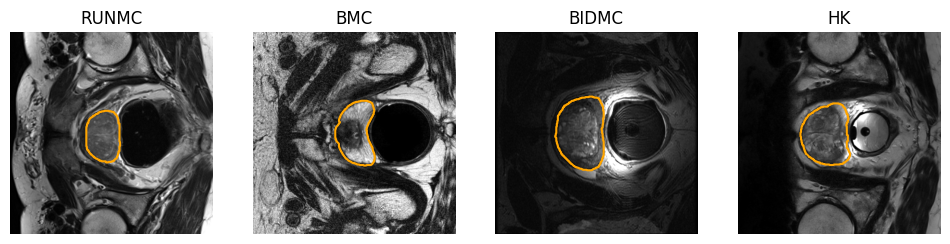

In [10]:
# One mid-prostate slice per hospital: same organ, different scanners
show = [train_vols[0]] + [next(v for v in test_vols if v["site"] == s) for s in TEST_SITES]
fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3))
for ax, v in zip(axes, show):
    z = int(v["gt"].sum((1, 2)).argmax())
    ax.imshow(v["img"][z], cmap="gray"); ax.contour(v["gt"][z], [0.5], colors="orange")
    ax.set_title(v["site"]); ax.axis("off")

## 3 · Proposer: small 2D U-Net trained on RUNMC

It only has to say roughly *where* the prostate is. 24 RUNMC volumes for training, the rest for validation.

In [11]:
def block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                         nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())

class UNet(nn.Module):
    def __init__(self, ch=(32, 64, 128, 256)):
        super().__init__()
        self.down = nn.ModuleList([block(i, o) for i, o in zip((1,) + ch[:-1], ch)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in reversed(range(len(ch) - 1))])
        self.dec = nn.ModuleList([block(2 * ch[i], ch[i]) for i in reversed(range(len(ch) - 1))])
        self.head = nn.Conv2d(ch[0], 1, 1)

    def forward(self, x):
        skips = []
        for i, d in enumerate(self.down):
            x = d(x if i == 0 else F.max_pool2d(x, 2)); skips.append(x)
        skips.pop()
        for up, dec in zip(self.up, self.dec):
            x = dec(torch.cat([up(x), skips.pop()], 1))
        return self.head(x)

def to_input(img):   # (D,H,W) volume -> (D,1,256,256), z-scored
    x = torch.from_numpy((img - img.mean()) / (img.std() + 1e-6)).float()[:, None]
    return F.interpolate(x, size=(256, 256), mode="bilinear")

@torch.no_grad()
def predict(img):    # proposer probability map, original size
    unet.eval()
    p = torch.sigmoid(unet(to_input(img).to(DEVICE))).cpu()
    return F.interpolate(p, size=img.shape[1:], mode="bilinear")[:, 0].numpy()

def dice(a, b):
    s = a.sum() + b.sum()
    return 1.0 if s == 0 else 2 * (a & b).sum() / s

tr, val = train_vols[:24], train_vols[24:]
X = torch.cat([to_input(v["img"]) for v in tr])
Y = torch.cat([F.interpolate(torch.from_numpy(v["gt"][:, None].astype(np.float32)), size=(256, 256)) for v in tr])

unet = UNet().to(DEVICE)
opt = torch.optim.Adam(unet.parameters(), lr=1e-3)
for ep in range(EPOCHS):
    unet.train()
    for idx in torch.randperm(len(X)).split(16):
        x, y = X[idx].to(DEVICE), Y[idx].to(DEVICE)
        if np.random.rand() < 0.5: x, y = x.flip(-1), y.flip(-1)                      # flip
        x = x * (0.85 + 0.3 * torch.rand(len(x), 1, 1, 1, device=DEVICE))           # intensity jitter
        logit = unet(x); p = torch.sigmoid(logit)
        loss = F.binary_cross_entropy_with_logits(logit, y) + 1 - (2 * (p * y).sum() + 1) / (p.sum() + y.sum() + 1)
        opt.zero_grad(); loss.backward(); opt.step()
    if (ep + 1) % 5 == 0:
        print(f"epoch {ep + 1}: loss {loss.item():.3f}, RUNMC val Dice {np.mean([dice(predict(v['img']) > 0.5, v['gt']) for v in val]):.3f}")

for v in test_vols:
    v["prob"] = predict(v["img"])

epoch 5: loss 0.700, RUNMC val Dice 0.628
epoch 10: loss 0.288, RUNMC val Dice 0.759
epoch 15: loss 0.333, RUNMC val Dice 0.703
epoch 20: loss 0.127, RUNMC val Dice 0.840


## 4 · MedSAM (frozen)

The image encoder runs once per slice (cached); the light mask decoder runs once per box and also returns MedSAM's
predicted IoU, used as the mask **confidence**.

In [12]:
from segment_anything import sam_model_registry

CKPT = WORK / "medsam_vit_b.pth"
if not CKPT.exists():
    try:
        gdown.download(id="1UAmWL88roYR7wKlnApw5Bcuzf2iQgk6_", output=str(CKPT))   # official MedSAM checkpoint
    except Exception as e:
        print("Google Drive failed:", e)
if not CKPT.exists():   # unofficial mirror, only if Google Drive refuses
    torch.hub.download_url_to_file("https://huggingface.co/spaces/dennistrujillo/MedSAMTest/resolve/main/medsam_vit_b.pth", str(CKPT))
medsam = sam_model_registry["vit_b"](checkpoint=str(CKPT)).to(DEVICE).eval()

@torch.no_grad()
def embedding(v, d):   # cached MedSAM embedding of slice d
    v.setdefault("emb", {})
    if d not in v["emb"]:
        x = resize(v["img"][d], (1024, 1024), order=3, preserve_range=True)
        x = (x - x.min()) / (x.max() - x.min() + 1e-8)
        x = torch.tensor(x, dtype=torch.float32, device=DEVICE)[None, None].repeat(1, 3, 1, 1)
        v["emb"][d] = medsam.image_encoder(x)
    return v["emb"][d]

@torch.no_grad()
def segment(emb, boxes, H, W):   # boxes [[x0, y0, x1, y1], ...] -> masks (B,H,W), confidence (B,)
    b = torch.tensor(boxes, dtype=torch.float32, device=DEVICE) * torch.tensor([1024 / W, 1024 / H] * 2, device=DEVICE)
    sparse, dense = medsam.prompt_encoder(points=None, boxes=b[:, None], masks=None)
    logits, iou = medsam.mask_decoder(image_embeddings=emb, image_pe=medsam.prompt_encoder.get_dense_pe(),
                                      sparse_prompt_embeddings=sparse, dense_prompt_embeddings=dense,
                                      multimask_output=False)
    masks = F.interpolate(logits, size=(H, W), mode="bilinear")[:, 0] > 0
    return masks.cpu().numpy(), iou[:, 0].cpu().numpy()

def bbox(mask, margin=0):
    ys, xs = np.where(mask); H, W = mask.shape
    return [max(xs.min() - margin, 0), max(ys.min() - margin, 0), min(xs.max() + margin, W - 1), min(ys.max() + margin, H - 1)]

# Sanity check: with the true box, MedSAM should be accurate (2D Dice > ~0.8)
v = test_vols[0]; z = int(v["gt"].sum((1, 2)).argmax())
m, c = segment(embedding(v, z), [bbox(v["gt"][z])], *v["gt"].shape[1:])
print(f"True box on {v['site']}/{v['case']} slice {z}: Dice {dice(m[0], v['gt'][z]):.3f}, MedSAM confidence {c[0]:.2f}")

Downloading...
From (original): https://drive.google.com/uc?id=1UAmWL88roYR7wKlnApw5Bcuzf2iQgk6_
From (redirected): https://drive.google.com/uc?id=1UAmWL88roYR7wKlnApw5Bcuzf2iQgk6_&confirm=t&uuid=0d4bb0b6-7348-4bf7-ae91-4e4dcf34bc1d
To: /kaggle/working/pherosam/medsam_vit_b.pth
100%|██████████| 375M/375M [00:02<00:00, 129MB/s] 


True box on BMC/Case00 slice 10: Dice 0.946, MedSAM confidence 0.60


## 5 · Candidates per slice

On each slice near the prostate: threshold the proposer map at 0.5 / 0.3 / 0.7, box the largest blob (0 and 6 px margin),
keep up to 5 boxes, and add a **"no object"** option (index 0). Then:

- **confidence** of a candidate = MedSAM predicted IoU (for "no object": 1 − max proposer probability)
- **smoothness** between candidates on neighbouring slices = mask IoU (0.5 if either is "no object")

In [13]:
def candidate_boxes(prob):
    boxes = []
    for thr in (0.5, 0.3, 0.7):
        lab, n = ndimage.label(prob > thr)
        if n == 0: continue
        blob = lab == 1 + np.argmax(np.bincount(lab.ravel())[1:])   # largest connected component
        if blob.sum() < 30: continue
        for margin in (0, 6):
            b = bbox(blob, margin)
            if b not in boxes: boxes.append(b)
    return boxes[:5]

def pairwise_iou(A, B):   # IoU between every mask in A and every mask in B
    a, b = A.reshape(len(A), -1).astype(np.float32), B.reshape(len(B), -1).astype(np.float32)
    inter = a @ b.T
    k = inter / np.maximum(a.sum(1)[:, None] + b.sum(1)[None] - inter, 1)
    k[0, :] = k[:, 0] = 0.5   # transitions involving "no object" are neutral
    return k

def build_candidates(v):
    D, H, W = v["gt"].shape
    maxp = v["prob"].max((1, 2))
    on = np.where(maxp > 0.3)[0]
    if len(on) == 0: on = [maxp.argmax()]
    v["slices"] = list(range(max(min(on) - 2, 0), min(max(on) + 2, D - 1) + 1))   # search window
    v["masks"], v["conf"] = [], []
    for d in v["slices"]:
        masks, conf = [np.zeros((H, W), bool)], [1 - maxp[d]]   # index 0 = "no object"
        boxes = candidate_boxes(v["prob"][d])
        if boxes:
            m, c = segment(embedding(v, d), boxes, H, W)
            masks += list(m); conf += list(c)
        v["masks"].append(np.array(masks)); v["conf"].append(np.array(conf))
    v["smooth"] = [pairwise_iou(a, b) for a, b in zip(v["masks"][:-1], v["masks"][1:])]

for v in test_vols:
    build_candidates(v)
    print(f"{v['site']}/{v['case']}: {len(v['slices'])} slices searched, "
          f"{np.mean([len(c) for c in v['conf']]):.1f} candidates per slice")

BMC/Case00: 32 slices searched, 3.3 candidates per slice
BMC/Case01: 16 slices searched, 4.4 candidates per slice
BIDMC/Case00: 47 slices searched, 5.9 candidates per slice
BIDMC/Case02: 54 slices searched, 5.9 candidates per slice
HK/Case38: 24 slices searched, 3.8 candidates per slice
HK/Case39: 24 slices searched, 5.3 candidates per slice


## 6 · Selection methods

A *path* picks one candidate index per slice. All methods use the same label-free fitness:

$$F = \text{mean confidence} + \text{mean smoothness}$$

**MMAS** (Max–Min Ant System): each ant walks slice by slice choosing candidate $j$ after $i$ with probability
$\propto \tau_{ij}^{\alpha}\,\eta_j^{\beta}\,(\kappa_{ij}+0.05)^{\gamma}$ ($\tau$ pheromone, $\eta$ confidence, $\kappa$ smoothness).
After each round the pheromone evaporates, the round's best ant deposits $F$ on its edges, and $\tau$ is clipped to $[\tau_{min}, \tau_{max}]$.

Because this fitness only links *neighbouring* slices, **DP (Viterbi) finds the exact optimum** — it is the reference MMAS should reach.

In [14]:
def fitness(v, path):
    conf = np.mean([c[j] for c, j in zip(v["conf"], path)])
    smooth = np.mean([k[i, j] for k, i, j in zip(v["smooth"], path[:-1], path[1:])]) if len(path) > 1 else 0.0
    return conf + smooth

def to_volume(v, path):
    out = np.zeros(v["gt"].shape, bool)
    for d, m, j in zip(v["slices"], v["masks"], path):
        out[d] = m[j]
    return out

def best_box(v):   # each slice on its own: the most confident candidate
    return [int(np.argmax(c)) for c in v["conf"]]

def dp_viterbi(v):   # exact maximiser of F
    L = len(v["conf"]); a, b = 1 / L, 1 / max(L - 1, 1)
    score, back = a * v["conf"][0], []
    for t in range(1, L):
        cand = score[:, None] + b * v["smooth"][t - 1] + a * v["conf"][t][None]
        back.append(cand.argmax(0)); score = cand.max(0)
    path = [int(score.argmax())]
    for bp in reversed(back):
        path.append(int(bp[path[-1]]))
    return path[::-1]

def random_search(v, rng, budget):
    best, best_f, curve = None, -np.inf, []
    for _ in range(budget):
        p = [int(rng.integers(len(c))) for c in v["conf"]]
        f = fitness(v, p)
        if f > best_f: best, best_f = p, f
        curve.append(best_f)
    return best, curve

def mmas(v, rng):
    L = len(v["conf"])
    eta = [np.maximum(c, 1e-3) ** BETA for c in v["conf"]]
    kap = [(k + 0.05) ** GAMMA for k in v["smooth"]]
    best = best_box(v); best_f = fitness(v, best)
    tau = [np.full(len(eta[0]), best_f / RHO)] + [np.full(k.shape, best_f / RHO) for k in kap]   # start at tau_max
    curve = []
    for _ in range(N_ROUNDS):
        round_best, round_f = None, -np.inf
        for _ in range(N_ANTS):
            w = tau[0] ** ALPHA * eta[0]
            path = [rng.choice(len(w), p=w / w.sum())]
            for t in range(1, L):
                w = tau[t][path[-1]] ** ALPHA * eta[t] * kap[t - 1][path[-1]]
                path.append(rng.choice(len(w), p=w / w.sum()))
            f = fitness(v, path)
            if f > round_f: round_best, round_f = path, f
            if f > best_f: best, best_f = path, f
            curve.append(best_f)
        # evaporate, round-best ant deposits, clip to [tau_min, tau_max]
        tau_max = best_f / RHO; tau_min = 0.05 * tau_max
        for t in range(L):
            tau[t] *= 1 - RHO
        tau[0][round_best[0]] += round_f
        for t in range(1, L):
            tau[t][round_best[t - 1], round_best[t]] += round_f
        for t in range(L):
            np.clip(tau[t], tau_min, tau_max, out=tau[t])
    return [int(j) for j in best], curve

def oracle_boxes(v):   # upper bound: MedSAM given the true box on every prostate slice
    out = np.zeros(v["gt"].shape, bool)
    for d in np.where(v["gt"].any((1, 2)))[0]:
        out[d] = segment(embedding(v, d), [bbox(v["gt"][d])], *out.shape[1:])[0][0]
    return out

## 7 · Run and results

In [15]:
rows, curves = [], {"MMAS": [], "Random search": []}
for v in test_vols:
    rng = np.random.default_rng(0)
    p_dp = dp_viterbi(v); f_dp = fitness(v, p_dp)
    p_rs, c_rs = random_search(v, rng, N_ANTS * N_ROUNDS)
    p_aco, c_aco = mmas(v, rng)
    curves["Random search"].append(np.array(c_rs) / f_dp); curves["MMAS"].append(np.array(c_aco) / f_dp)
    paths = {"MedSAM best box": best_box(v), "Random search": p_rs, "DP (Viterbi)": p_dp, "MMAS": p_aco}
    v["pred"] = {"Proposer only": v["prob"] > 0.5, **{m: to_volume(v, p) for m, p in paths.items()},
                 "Oracle boxes (upper bound)": oracle_boxes(v)}
    for m, mask in v["pred"].items():
        rows.append(dict(site=v["site"], case=v["case"], method=m, dice=dice(mask, v["gt"]),
                         fitness=fitness(v, paths[m]) if m in paths else np.nan))

res = pd.DataFrame(rows)
res.to_csv(OUT / "results.csv", index=False)
METHODS = list(v["pred"])
table = res.pivot_table(index="method", columns="site", values="dice").reindex(METHODS)
table["all"] = res.groupby("method").dice.mean()
table["fitness F"] = res.groupby("method").fitness.mean()
table.round(3)

site,BIDMC,BMC,HK,all,fitness F
method,,,,,
Proposer only,0.340,0.340,0.812,0.497,NaN
MedSAM best box,0.331,0.381,0.802,0.505,1.097
Random search,0.358,0.365,0.795,0.506,1.108
DP (Viterbi),0.321,0.361,0.808,0.496,1.172
MMAS,0.337,0.360,0.803,0.500,1.137
Oracle boxes (upper bound),0.891,0.927,0.893,0.904,NaN


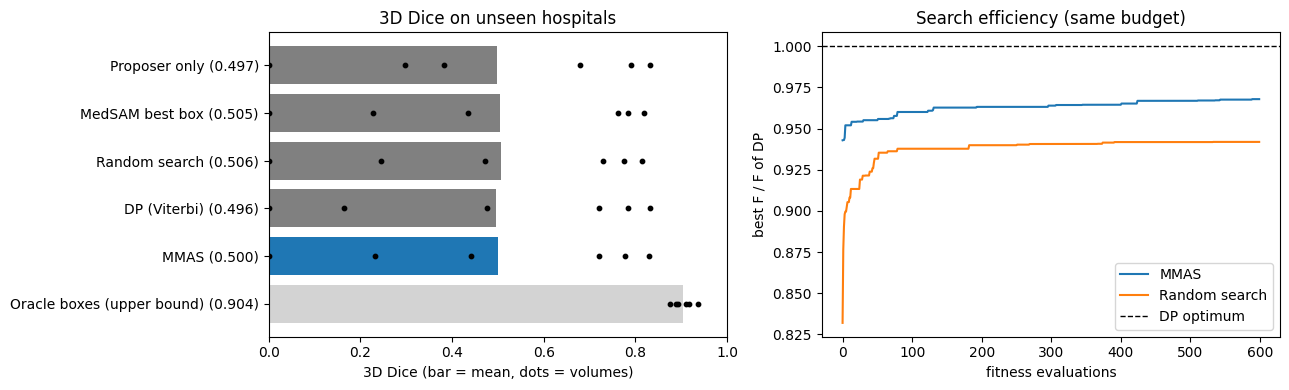

In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
means = table["all"]
a1.barh([f"{m} ({means[m]:.3f})" for m in METHODS], means,
         color=["tab:blue" if m == "MMAS" else "lightgray" if "Oracle" in m else "gray" for m in METHODS])
for y, m in enumerate(METHODS):
    d = res[res.method == m].dice
    a1.scatter(d, [y] * len(d), color="k", s=10, zorder=3)
a1.invert_yaxis(); a1.set_xlim(0, 1); a1.set_xlabel("3D Dice (bar = mean, dots = volumes)")
a1.set_title("3D Dice on unseen hospitals")

for name, color in [("MMAS", "tab:blue"), ("Random search", "tab:orange")]:
    a2.plot(np.mean(curves[name], 0), color=color, label=name)
a2.axhline(1, color="k", ls="--", lw=1, label="DP optimum")
a2.set_xlabel("fitness evaluations"); a2.set_ylabel("best F / F of DP"); a2.legend()
a2.set_title("Search efficiency (same budget)")
fig.tight_layout(); fig.savefig(OUT / "results.png", dpi=150)

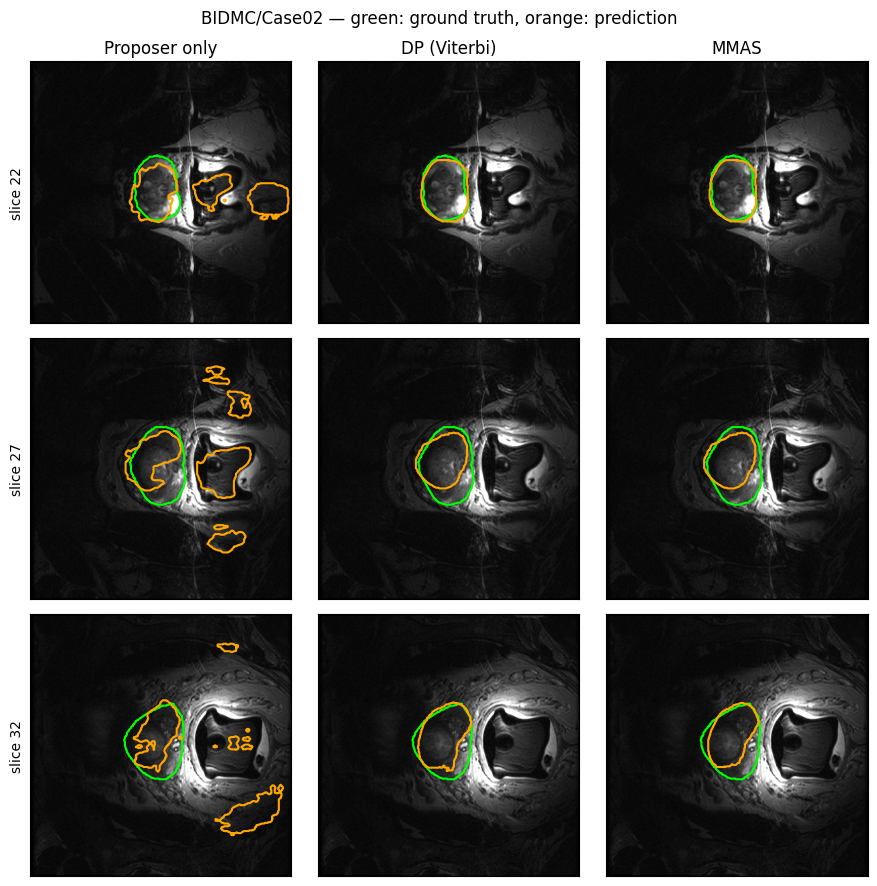

In [17]:
# Qualitative example: the volume where MMAS beats the plain proposer the most
gain = res[res.method == "MMAS"].dice.values - res[res.method == "Proposer only"].dice.values
v = test_vols[int(np.argmax(gain))]
zs = np.where(v["gt"].any((1, 2)))[0]; zs = [zs[len(zs) // 4], zs[len(zs) // 2], zs[3 * len(zs) // 4]]
show = ["Proposer only", "DP (Viterbi)", "MMAS"]
fig, axes = plt.subplots(len(zs), len(show), figsize=(3 * len(show), 3 * len(zs)))
for r, z in enumerate(zs):
    for c, m in enumerate(show):
        ax = axes[r, c]; ax.imshow(v["img"][z], cmap="gray")
        ax.contour(v["gt"][z], [0.5], colors="lime")
        if v["pred"][m][z].any(): ax.contour(v["pred"][m][z], [0.5], colors="orange")
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(m)
        if c == 0: ax.set_ylabel(f"slice {z}")
fig.suptitle(f"{v['site']}/{v['case']} — green: ground truth, orange: prediction")
fig.tight_layout(); fig.savefig(OUT / "qualitative.png", dpi=150)